### Stock Market Analysis

In [1]:
!pip install yfinance

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

sns.set_style("whitegrid")

print("Stock Market Analysis Started!")


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Stock Market Analysis Started!


In [2]:
stock = yf.download(
    "AAPL",
    period="1y",
    interval="1d",
    auto_adjust=True
)

print("Stock Dataset Loaded!")

[*********************100%***********************]  1 of 1 completed

Stock Dataset Loaded!


In [3]:
print(stock.head())

print("\nShape:", stock.shape)

print("\nColumns:")
print(stock.columns)

print("\nDataset Information:")
stock.info()

Price            Close        High         Low        Open    Volume
Ticker            AAPL        AAPL        AAPL        AAPL      AAPL
Date                                                                
2025-11-07  267.481903  271.287851  265.788148  268.806995  48227400
2025-11-10  268.698578  272.986923  266.733925  268.229853  41312400
2025-11-11  274.502808  275.161020  269.067590  269.077573  46208300
2025-11-12  272.727661  274.981536  270.962477  274.253507  48398000
2025-11-13  272.209076  275.948896  271.351395  273.365900  49602800

Shape: (251, 5)

Columns:
MultiIndex([( 'Close', 'AAPL'),
            (  'High', 'AAPL'),
            (   'Low', 'AAPL'),
            (  'Open', 'AAPL'),
            ('Volume', 'AAPL')],
           names=['Price', 'Ticker'])

Dataset Information:
<class 'pandas.DataFrame'>
DatetimeIndex: 251 entries, 2025-11-07 to 2026-11-06
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  ----- 

In [4]:
data = stock.copy()

data = data.drop_duplicates()

data = data.dropna()

print("Data Cleaning Completed!")

print("Missing Values:")
print(data.isnull().sum())

Data Cleaning Completed!
Missing Values:
Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64


In [5]:
print("Average Closing Price:", data["Close"].mean())

print("Highest Closing Price:", data["Close"].max())

print("Lowest Closing Price:", data["Close"].min())

print("Total Trading Days:", len(data))

Average Closing Price: Ticker
AAPL    292.620316
dtype: float64
Highest Closing Price: Ticker
AAPL    349.51001
dtype: float64
Lowest Closing Price: Ticker
AAPL    246.030319
dtype: float64
Total Trading Days: 251


In [6]:
data["MA_20"] = data["Close"].rolling(20).mean()

data["MA_50"] = data["Close"].rolling(50).mean()

data[["Close", "MA_20", "MA_50"]].tail()

Price,Close,MA_20,MA_50
Ticker,AAPL,,
Date,,,
2026-11-02,338.320007,342.355002,333.620201
2026-11-03,331.899994,342.268501,334.051401
2026-11-04,349.510010,342.910501,334.843601
2026-11-05,344.170013,343.098001,335.458001
2026-11-06,342.369995,343.384500,336.013801


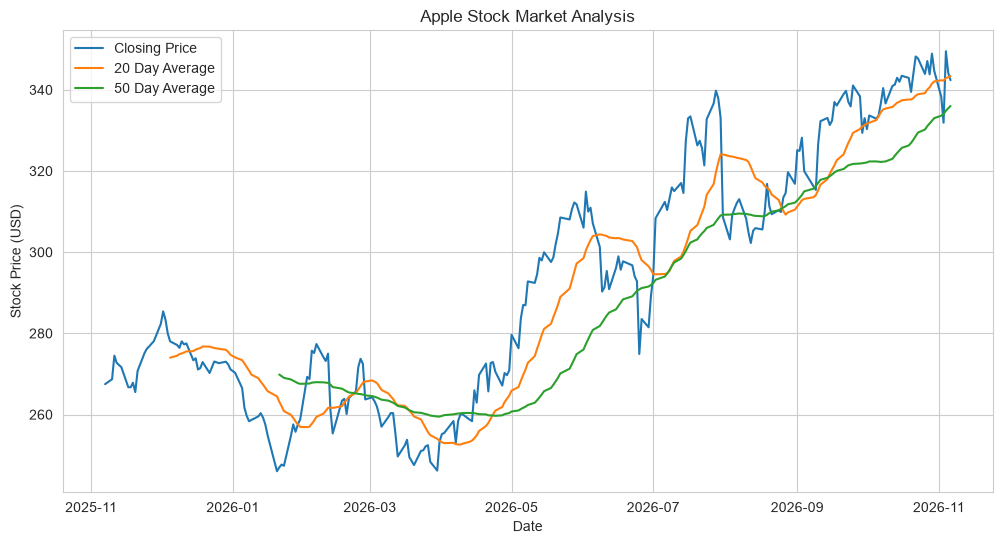

In [7]:
plt.figure(figsize=(12, 6))

plt.plot(data.index, data["Close"], label="Closing Price")
plt.plot(data.index, data["MA_20"], label="20 Day Average")
plt.plot(data.index, data["MA_50"], label="50 Day Average")

plt.title("Apple Stock Market Analysis")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")

plt.legend()
plt.show()

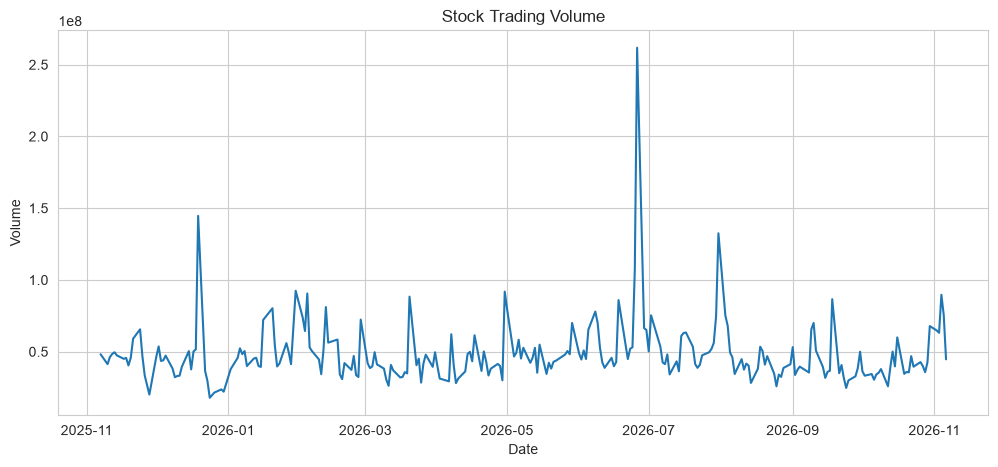

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(data.index, data["Volume"])

plt.title("Stock Trading Volume")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.show()

In [9]:
print("========== STOCK MARKET REPORT ==========")

print("Stock Name: Apple (AAPL)")

print("Average Price:", round(data["Close"].mean(), 2))

print("Highest Price:", round(data["Close"].max(), 2))

print("Lowest Price:", round(data["Close"].min(), 2))

print("Trading Days:", len(data))

print("Stock Analysis Completed!")

========== STOCK MARKET REPORT ==========
Stock Name: Apple (AAPL)
Average Price: Ticker
AAPL    292.62
dtype: float64
Highest Price: Ticker
AAPL    349.51
dtype: float64
Lowest Price: Ticker
AAPL    246.03
dtype: float64
Trading Days: 251
Stock Analysis Completed!


In [10]:
data.to_csv("Stock_Market_Analysis.csv")

print("Stock Market CSV File Saved Successfully!")

Stock Market CSV File Saved Successfully!
